# Combination warning lead time: three-day versus seven-day

Use the combinations from the presentation: individual models, each pair, and all three. OR daily signals before one shared7-daycooldown and one-to-oneevent matching. Same585ZIPs andSep1–Dec24 2020 forecastdates. Use Notebook37 calibration thresholds, no new fitting. Lead means include only detected events. Compare identical detected events separately to distinguish subset changes.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/"Weikun").is_dir(): ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"mentor_followup_outputs"/"2026-11-04"/"combined_warning_lead"

In [2]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score,precision_recall_curve

def event_labels(counts):
    """Causal labels; onset is confirmation, never backdated."""
    s=pd.Series(np.asarray(counts,dtype=float))
    ma=s.rolling(3,min_periods=3).mean()
    hist=ma.shift(3).rolling(28,min_periods=28)
    mean,sd=hist.mean(),hist.std(ddof=1)
    threshold=mean+2*sd
    qualify=(ma>threshold)&(s.rolling(3).sum()>=5)&threshold.notna()
    valid=threshold.notna().to_numpy()
    # Smooth continuous excess with the same sign as the two qualification gates.
    scale=np.maximum(sd.to_numpy(),1.)
    margin=np.minimum((ma.to_numpy()-threshold.to_numpy())/scale,
                      (s.rolling(3).sum().to_numpy()-5+1e-9)/(3*scale))
    active=np.zeros(len(s),bool);onset=np.zeros(len(s),bool)
    in_event=False;off=0
    for k in range(len(s)):
        if in_event:
            off=0 if qualify.iloc[k] else off+1
            if off>=7:in_event=False;off=0
        elif k>0 and qualify.iloc[k] and qualify.iloc[k-1]:
            in_event=True;onset[k]=True
        active[k]=in_event
    return dict(ma=ma.to_numpy(),threshold=threshold.to_numpy(),sd=sd.to_numpy(),
                qualify=qualify.to_numpy(),valid=valid,margin=margin,active=active,onset=onset)


NAMES=['Dynamic Panel FE','XGBoost','Random Forest']

def score_paths(counts,pos,pred):
    H=pred.shape[2];scores=np.empty((len(counts),len(pos)));margins_saved=[]
    for j,k in enumerate(pos):
        hist=counts[:,k-32:k+1];seq=np.concatenate([hist,pred[:,j,:]],axis=1)
        means=np.full(seq.shape,np.nan);means[:,2:]=(seq[:,2:]+seq[:,1:-1]+seq[:,:-2])/3
        margins=[]
        for d in range(32,33+H):
            baseline=means[:,d-30:d-2];assert baseline.shape[1]==28 and np.isfinite(baseline).all()
            mu=baseline.mean(axis=1);sd=baseline.std(axis=1,ddof=1);scale=np.maximum(sd,1.)
            margins.append(np.minimum((means[:,d]-mu-2*sd)/scale,(seq[:,d-2:d+1].sum(axis=1)-5+1e-9)/(3*scale)))
        margins=np.stack(margins,axis=1)
        scores[:,j]=np.max(np.minimum(margins[:,:-1],margins[:,1:]),axis=1)
        if j in [0,len(pos)//2,len(pos)-1]:
            for z in [0,100,len(counts)-1]:assert np.allclose(margins[z],event_labels(seq[z])['margin'][-(H+1):])
    assert np.isfinite(scores).all();return scores

def evaluate(score,eligible,onsets,forecast_dates,calendar,threshold,H):
    alarms=[];events=[]
    for z in range(len(score)):
        ed=calendar[onsets[z]]
        covered=[d for d in ed if np.any(eligible[z]&((d-forecast_dates).astype('timedelta64[D]').astype(int)>=1)&((d-forecast_dates).astype('timedelta64[D]').astype(int)<=H))]
        matched=set();last=None
        for j,d in enumerate(forecast_dates):
            if not eligible[z,j] or not score[z,j]>threshold:continue
            if last is not None and int((d-last)/np.timedelta64(1,'D'))<7:continue
            last=d;candidates=[e for e in covered if e not in matched and 1<=int((e-d)/np.timedelta64(1,'D'))<=H]
            e=min(candidates) if candidates else None
            if e is not None:matched.add(e)
            alarms.append(dict(region_index=z,daily_forecast_date=str(d),matched_event_date=str(e) if e is not None else '',true_warning=e is not None,lead_days=float((e-d)/np.timedelta64(1,'D')) if e is not None else np.nan))
        for e in covered:events.append(dict(region_index=z,event_date=str(e),detected=e in matched))
    a=pd.DataFrame(alarms,columns=['region_index','daily_forecast_date','matched_event_date','true_warning','lead_days']);ev=pd.DataFrame(events,columns=['region_index','event_date','detected'])
    tp=int(a.true_warning.sum());fp=len(a)-tp
    assert tp==int(ev.detected.sum())
    met=dict(eligible_events=len(ev),detected_events=tp,warning_episodes=len(a),false_warning_episodes=fp,event_detection_rate=tp/len(ev) if len(ev) else np.nan,warning_precision=tp/len(a) if len(a) else np.nan,mean_lead_days=a.lead_days.mean(),median_lead_days=a.lead_days.median(),false_warnings_per_30_at_risk_zip_days=fp*30/eligible.sum(),at_risk_zip_days=int(eligible.sum()))
    return met,a,ev


def run_combined_lead(root,output):
    root=Path(root);out=Path(output);out.mkdir(parents=True,exist_ok=True);(out/'figures').mkdir(exist_ok=True)
    source=root/'mentor_followup_outputs/2026-11-04/seven_day_warnings'
    labels=pd.read_csv(root/'outbreak_task_outputs/case_surge_v1_20261101/daily_event_labels_2020.csv.gz',dtype={'zip':str},parse_dates=['date'])
    original=pd.read_csv(source/'warning_horizon_metrics.csv').query("phase=='assessment'")
    rows=[];leadrows=[];events_by={};alarms_by={}
    configs=[('DP',[0]),('XGBoost',[1]),('RF',[2]),('DP + XGBoost',[0,1]),('DP + RF',[0,2]),('XGBoost + RF',[1,2]),('All three',[0,1,2])]
    for H in [3,7]:
        frames=[pd.read_csv(source/(name.split()[0]+f'_{H}day_risk.csv.gz'),dtype={'zip':str}).sort_values(['zip','daily_forecast_date']).reset_index(drop=True) for name in NAMES]
        for f in frames[1:]:
            for key in ['zip','daily_forecast_date','eligible']:assert f[key].equals(frames[0][key]),key
        ids=np.sort(frames[0].zip.unique());fd=np.sort(frames[0].daily_forecast_date.unique()).astype('datetime64[D]');n=len(fd)
        eligible=frames[0].eligible.to_numpy().reshape(len(ids),n);sc=np.stack([f.risk_score.to_numpy().reshape(len(ids),n) for f in frames])
        q=original.query('horizon_days==@H').set_index('model').threshold.reindex(NAMES).to_numpy();votes=sc>q[:,None,None]
        p=labels.pivot(index='zip',columns='date',values='onset').reindex(ids);calendar=p.columns.to_numpy().astype('datetime64[D]');onsets=p.to_numpy(bool)
        mask=(fd>=np.datetime64('2020-09-01'))&(fd<=np.datetime64('2020-12-24'));assert mask.sum()==115
        for rule,members in configs:
            combined=np.any(votes[members],axis=0)
            met,a,ev=evaluate(combined[:,mask].astype(float),eligible[:,mask],onsets,fd[mask],calendar,.5,H)
            if len(members)==1:
                ref=original[(original.model==NAMES[members[0]])&(original.horizon_days==H)].iloc[0]
                for key in ['detected_events','warning_episodes','false_warning_episodes','mean_lead_days','median_lead_days']:assert np.isclose(met[key],ref[key]),key
            rows.append(dict(rule=rule,horizon_days=H,**met));events_by[(rule,H)]=ev;alarms_by[(rule,H)]=a
            a['zip']=a.region_index.map(dict(enumerate(ids)));a.to_csv(out/(rule.replace(' + ','_').replace(' ','_')+f'_{H}day_warnings.csv'),index=False)
            for lead in range(1,H+1):
                count=int((a.lead_days==lead).sum());leadrows.append(dict(rule=rule,horizon_days=H,lead_days=lead,events=count,share_of_detected=count/met['detected_events']))
    result=pd.DataFrame(rows);result.to_csv(out/'combined_warning_metrics_3_vs_7.csv',index=False);pd.DataFrame(leadrows).to_csv(out/'combined_lead_distribution.csv',index=False)
    # Compare lead on the same events detected by both horizons, separately.
    matched=[]
    for rule,_ in configs:
        a=alarms_by[(rule,3)].query('true_warning')[['region_index','matched_event_date','lead_days']]
        b=alarms_by[(rule,7)].query('true_warning')[['region_index','matched_event_date','lead_days']]
        c=a.merge(b,on=['region_index','matched_event_date'],suffixes=('_3','_7'),validate='one_to_one')
        matched.append(dict(rule=rule,events_detected_by_both=len(c),mean_lead_3=c.lead_days_3.mean(),mean_lead_7=c.lead_days_7.mean(),mean_paired_difference=(c.lead_days_7-c.lead_days_3).mean(),earlier_7day=int((c.lead_days_7>c.lead_days_3).sum()),same_lead=int((c.lead_days_7==c.lead_days_3).sum()),later_7day=int((c.lead_days_7<c.lead_days_3).sum())))
    pd.DataFrame(matched).to_csv(out/'same_detected_event_lead_comparison.csv',index=False)
    plt.rcParams.update({'font.family':'Arial','font.size':12,'axes.spines.top':False,'axes.spines.right':False,'text.color':'#173654','axes.labelcolor':'#173654','xtick.color':'#173654','ytick.color':'#173654'})
    groups=[('Individual models',['DP','XGBoost','RF'],['DP','XGBoost','RF']),('Starting model: Dynamic Panel',['DP','DP + XGBoost','DP + RF','All three'],['Alone','+ XGB','+ RF','+ XGB + RF']),('Starting model: XGBoost',['XGBoost','DP + XGBoost','XGBoost + RF','All three'],['Alone','+ DP','+ RF','+ DP + RF']),('Starting model: Random Forest',['RF','DP + RF','XGBoost + RF','All three'],['Alone','+ DP','+ XGB','+ DP + XGB'])]
    fig,axs=plt.subplots(2,2,figsize=(13.5,5.5));w=.34
    for ax,(title,rules,lab) in zip(axs.flat,groups):
        x=np.arange(len(rules))
        for j,H in enumerate([3,7]):
            v=result[result.horizon_days==H].set_index('rule').loc[rules,'mean_lead_days'];bars=ax.bar(x+(j-.5)*w,v,w,label=f'Next {H} days',color=['#64748B','#2563EB'][j]);ax.bar_label(bars,labels=[f'{z:.2f}' for z in v],padding=3,fontsize=11,fontweight='bold')
        ax.set(xticks=x,xticklabels=lab,ylim=(0,3),yticks=[0,1,2,3],ylabel='Mean warning lead time (days)',title=title);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
        if title=='Individual models':ax.legend(ncol=2,loc='upper left',fontsize=10)
    fig.tight_layout(h_pad=1.6,w_pad=2);fig.savefig(out/'figures/combined_lead_3_vs_7.png',dpi=230);plt.close(fig)
    protocol=dict(forecast_dates='2020-09-01 to 2020-12-24,115daily dates',regions=585,combination='OR on same ZIP/date before common7daycooldown andone-to-one earliest-eventmatching',thresholds='Retain Notebook37 calibration per model and horizon; all0',lead='Rule-defined event start minus matched alert date,onlydetected events',event_rule='Unchanged Notebook27 three-day smoothing;secondqualifyingday start',warning_horizons=[3,7],comparability='Different detected subsets. Same-detected-event timing comparison saved separately. Nativeeligible eventdenominators1039vs1125. Do notmix oldSep1-Dec28 three-day figures.',new_model_training=False,verified_individuals_reproduce_notebook37=True)
    (out/'protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
    (out/'RESULTS.md').write_text('# Combination warning lead time: three and seven day horizons\n\n'+result.round(5).to_markdown(index=False)+'\n\n## Same events detected under both horizons\n\n'+pd.DataFrame(matched).round(5).to_markdown(index=False)+'\n\n'+json.dumps(protocol,indent=2)+'\n\nRead lead with detection and false warnings, never alone. Longer matching range mechanically permits longer leads. Mean lead uses different detected subsets. Not a demonstration of warning before the first abnormal day or real-time onset availability. 2020 exploratory validation, no untouched test or significance claim.',encoding='utf-8')
    print(result[['rule','horizon_days','detected_events','mean_lead_days','median_lead_days']].to_string(index=False));return result,pd.DataFrame(matched)


In [3]:
metrics,matched=run_combined_lead(ROOT,OUTPUT)
display(metrics.round(4))
display(matched.round(4))

        rule  horizon_days  detected_events  mean_lead_days  median_lead_days
          DP             3              820        1.319512               1.0
     XGBoost             3              761        1.135348               1.0
          RF             3              831        1.238267               1.0
DP + XGBoost             3              826        1.325666               1.0
     DP + RF             3              840        1.348810               1.0
XGBoost + RF             3              833        1.241297               1.0
   All three             3              840        1.350000               1.0
          DP             7              918        2.028322               1.0
     XGBoost             7              793        1.327869               1.0
          RF             7              889        1.649044               1.0
DP + XGBoost             7              925        2.034595               1.0
     DP + RF             7              949        2.118019     

,rule,horizon_days,eligible_events,detected_events,warning_episodes,false_warning_episodes,event_detection_rate,warning_precision,mean_lead_days,median_lead_days,false_warnings_per_30_at_risk_zip_days,at_risk_zip_days
0,DP,3,1039,820,1229,409,0.7892,0.6672,1.3195,1.0,0.2296,53430
1,XGBoost,3,1039,761,918,157,0.7324,0.8290,1.1353,1.0,0.0882,53430
2,RF,3,1039,831,1097,266,0.7998,0.7575,1.2383,1.0,0.1494,53430
3,DP + XGBoost,3,1039,826,1241,415,0.7950,0.6656,1.3257,1.0,0.2330,53430
4,DP + RF,3,1039,840,1294,454,0.8085,0.6491,1.3488,1.0,0.2549,53430
5,XGBoost + RF,3,1039,833,1107,274,0.8017,0.7525,1.2413,1.0,0.1538,53430
6,All three,3,1039,840,1295,455,0.8085,0.6486,1.3500,1.0,0.2555,53430
7,DP,7,1125,918,1614,696,0.8160,0.5688,2.0283,1.0,0.3908,53430
8,XGBoost,7,1125,793,927,134,0.7049,0.8554,1.3279,1.0,0.0752,53430
9,RF,7,1125,889,1158,269,0.7902,0.7677,1.6490,1.0,0.1510,53430


,rule,events_detected_by_both,mean_lead_3,mean_lead_7,mean_paired_difference,earlier_7day,same_lead,later_7day
0,DP,820,1.3195,1.7451,0.4256,135,669,16
1,XGBoost,761,1.1353,1.1537,0.0184,7,753,1
2,RF,831,1.2383,1.3995,0.1613,56,771,4
3,DP + XGBoost,826,1.3257,1.7591,0.4334,139,670,17
4,DP + RF,840,1.3488,1.8167,0.4679,157,665,18
5,XGBoost + RF,833,1.2413,1.4058,0.1645,58,770,5
6,All three,840,1.3500,1.8143,0.4643,158,663,19


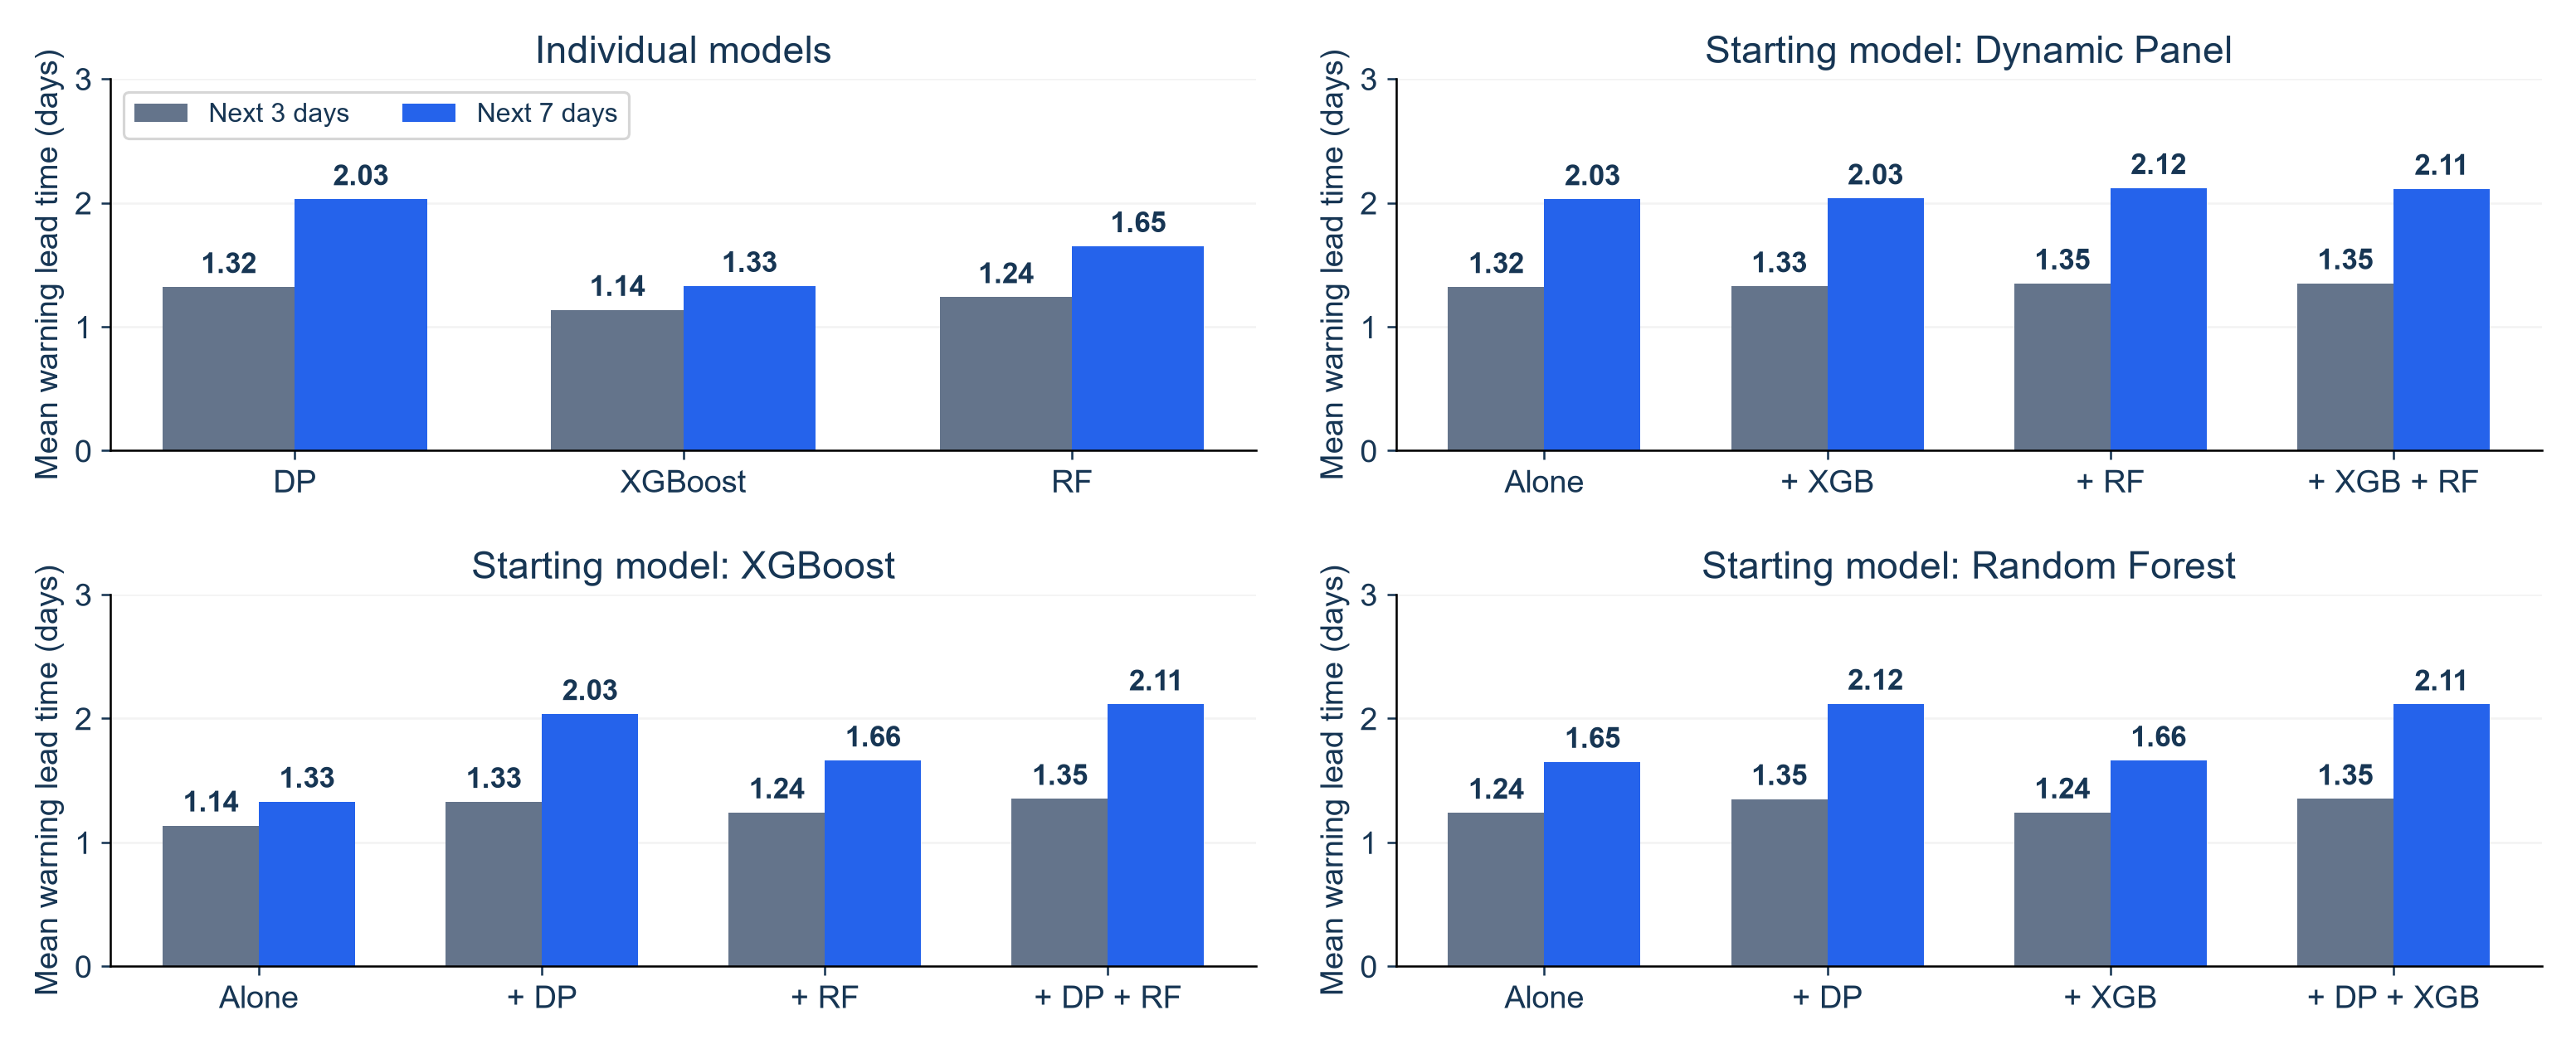

,rule,horizon_days,lead_days,events,share_of_detected
0,DP,3,1,600,0.7317
1,DP,3,2,178,0.2171
2,DP,3,3,42,0.0512
3,XGBoost,3,1,669,0.8791
4,XGBoost,3,2,81,0.1064
...,...,...,...,...,...
65,All three,7,3,62,0.0653
66,All three,7,4,43,0.0453
67,All three,7,5,43,0.0453
68,All three,7,6,36,0.0379


In [4]:
from IPython.display import Image,display
display(Image(filename=str(OUTPUT/"figures/combined_lead_3_vs_7.png")))
display(pd.read_csv(OUTPUT/"combined_lead_distribution.csv").round(4))